In [1]:
#Libraries
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
#Set time to extract historical data
years = 15
endDate = dt.datetime(2023, 9, 30)
startDate = endDate - dt.timedelta(days = 365*years)



In [3]:
#create a list for tickers
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [4]:
#download adjusted close prices
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate, auto_adjust = False, progress = False)
    adj_close_df[ticker] = data['Adj Close'].squeeze()
print(adj_close_df)

                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2008-10-03   79.638008  43.676697   82.589996   31.118189   39.761787
2008-10-06   75.581741  43.326088   84.279999   29.982864   38.376438
2008-10-07   72.196762  43.452568   87.269997   28.082062   36.033669
2008-10-08   70.377922  42.808777   89.419998   27.858431   35.344616
2008-10-09   65.462784  41.475361   89.900002   27.110142   33.125156
...                ...        ...         ...         ...         ...
2023-09-25  416.843506  62.013931  177.699997  353.581818  206.444565
2023-09-26  410.719513  61.951878  176.279999  348.272339  203.470596
2023-09-27  410.883484  61.730232  174.100006  349.088501  203.682327
2023-09-28  413.265594  61.889843  173.229996  352.008759  205.029755
2023-09-29  412.262604  61.863216  171.449997  352.264313  204.433044

[3773 rows x 5 columns]


In [5]:
#calculate daily log returns and drop na
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

                 SPY       BND       GLD       QQQ       VTI
Date                                                        
2008-10-06 -0.052277 -0.008060  0.020256 -0.037166 -0.035463
2008-10-07 -0.045820  0.002915  0.034862 -0.065495 -0.062990
2008-10-08 -0.025516 -0.014927  0.024338 -0.007995 -0.019308
2008-10-09 -0.072398 -0.031644  0.005354 -0.027228 -0.064853
2008-10-10 -0.024555 -0.030963 -0.077210 -0.006365 -0.029328
...              ...       ...       ...       ...       ...
2023-09-25  0.004196 -0.007407 -0.005164  0.004738  0.004017
2023-09-26 -0.014800 -0.001001 -0.008023 -0.015130 -0.014510
2023-09-27  0.000399 -0.003584 -0.012444  0.002341  0.001040
2023-09-28  0.005781  0.002582 -0.005010  0.008331  0.006594
2023-09-29 -0.002430 -0.000430 -0.010329  0.000726 -0.002915

[3772 rows x 5 columns]


In [6]:
#Create equally weighted portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
print(weights)

[0.2 0.2 0.2 0.2 0.2]


In [7]:
#calculate historical porfolio return
historical_returns = (log_returns*weights).sum(axis=1)
print(historical_returns)

Date
2008-10-06   -0.022542
2008-10-07   -0.027305
2008-10-08   -0.008682
2008-10-09   -0.038154
2008-10-10   -0.033684
                ...   
2023-09-25    0.000076
2023-09-26   -0.010693
2023-09-27   -0.002450
2023-09-28    0.003655
2023-09-29   -0.003076
Length: 3772, dtype: float64


In [8]:
#find x day historical retuns i.e. rolling averages
days = 30

range_returns = historical_returns.rolling(window = days).sum()
range_returns = range_returns.dropna()
print(range_returns)

Date
2008-11-14   -0.166835
2008-11-17   -0.158818
2008-11-18   -0.126396
2008-11-19   -0.154185
2008-11-20   -0.152093
                ...   
2023-09-25   -0.017732
2023-09-26   -0.031886
2023-09-27   -0.026593
2023-09-28   -0.015954
2023-09-29   -0.013153
Length: 3743, dtype: float64


In [9]:
#specify confidence interval and calculate VaR
confidence_interval = 0.95

VaR = -np.percentile(range_returns, 100 - (confidence_interval * 100))*portfolio_value
print(VaR)

46512.63659709529


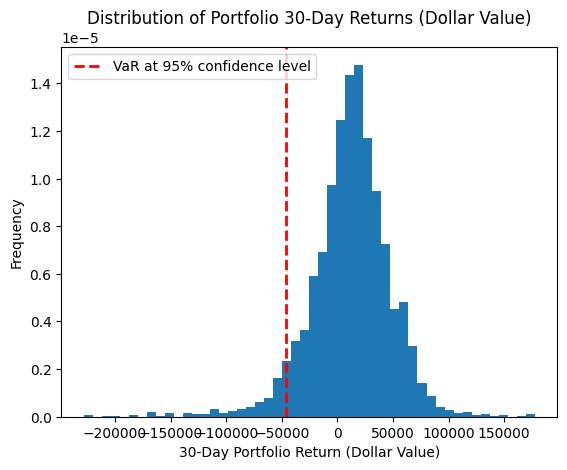

In [10]:
return_window = days
range_returns = historical_returns.rolling(window=return_window).sum()
range_returns = range_returns.dropna()

range_returns_dollar = range_returns * portfolio_value

plt.hist(range_returns_dollar.dropna(), bins=50, density=True)
plt.xlabel(f'{return_window}-Day Portfolio Return (Dollar Value)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {return_window}-Day Returns (Dollar Value)')
plt.axvline(-VaR, color='r', linestyle='dashed', linewidth=2, label=f'VaR at {confidence_interval:.0%} confidence level')
plt.legend()
plt.show()

## Expected Shortfall (Historical)
Expected Shortfall (ES, or CVaR) is the average loss on the days beyond VaR: it shows how bad losses are in the tail, not just where the tail starts.

In [11]:
es_table = []
for cl in [0.95, 0.99]:
    var_cut = np.percentile(range_returns, 100 * (1 - cl))
    VaR_cl = -var_cut * portfolio_value
    ES_cl = -range_returns[range_returns <= var_cut].mean() * portfolio_value
    es_table.append((cl, VaR_cl, ES_cl))

print(f'{"Confidence":<12}{"30-day VaR":>16}{"30-day ES":>16}')
for cl, v, e in es_table:
    print(f'{cl:<12.0%}{v:>16,.2f}{e:>16,.2f}')

Confidence        30-day VaR       30-day ES
95%                46,512.64       81,006.51
99%               108,588.11      146,774.02
